In [ ]:
!pip install ultralytics -q

import os
import cv2
import numpy as np
from pathlib import Path
from ultralytics import YOLO
from PIL import Image, ImageDraw, ImageFont
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from google.colab import files

import torch
import torch.nn as nn
from torchvision import models, transforms

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 19.0 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
from ultralytics import YOLO

# Model 1: detects the license plate region (has 'plate' class)
PLATE_DETECTOR_PATH  = '/content/drive/MyDrive/PlateDetection/best.pt'

# Model 2: recognizes characters on the cropped plate (has 0-9, A-Z classes)
CHAR_RECOGNIZER_PATH = '/content/drive/MyDrive/Characters_Digits_Detection/best.pt'

plate_model = YOLO(PLATE_DETECTOR_PATH)
char_model  = YOLO(CHAR_RECOGNIZER_PATH)

print("✅ Plate detector loaded:", PLATE_DETECTOR_PATH)
print("✅ Char recognizer loaded:", CHAR_RECOGNIZER_PATH)
print("\n📋 Plate model classes:", plate_model.names)
print("📋 Char model classes :", char_model.names)

✅ Plate detector loaded: /content/drive/MyDrive/PlateDetection/best.pt
✅ Char recognizer loaded: /content/drive/MyDrive/Characters_Digits_Detection/best.pt

📋 Plate model classes: {0: 'plate'}
📋 Char model classes : {0: '0', 1: '1', 2: '2', 3: '3', 4: '4', 5: '5', 6: '6', 7: '7', 8: '8', 9: '9', 10: 'A', 11: 'B', 12: 'C', 13: 'D', 14: 'E', 15: 'F', 16: 'G', 17: 'H', 18: 'I', 19: 'J', 20: 'K', 21: 'L', 22: 'M', 23: 'N', 24: 'O', 25: 'P', 26: 'Q', 27: 'R', 28: 'S', 29: 'T', 30: 'U', 31: 'V', 32: 'W', 33: 'X', 34: 'Y', 35: 'YY', 36: 'Z', 37: 'a'}


In [ ]:
# ============================================================
# Vehicle Make/Model Classifier  (EfficientNet-B4)
# ============================================================
# ⚠️  Update these paths if your files are in a subfolder on Drive
VEHICLE_MODEL_PATH = '/content/drive/MyDrive/vmmr_checkpoints/efficientnet_b4_best.pth'
CLASSES_TXT_PATH   = '/content/drive/MyDrive/vmmr_checkpoints/classes.txt'

with open(CLASSES_TXT_PATH, 'r') as f:
    vehicle_classes = [line.strip() for line in f if line.strip()]

num_vehicle_classes = len(vehicle_classes)
print(f"📋 Vehicle classes loaded: {num_vehicle_classes} classes")

vehicle_model = models.efficientnet_b4(weights=None)
vehicle_model.classifier = nn.Sequential(
    nn.Dropout(p=0.4, inplace=True),
    nn.Linear(1792, num_vehicle_classes)
)

checkpoint = torch.load(VEHICLE_MODEL_PATH, map_location='cpu')
vehicle_model.load_state_dict(checkpoint['model_state'])
vehicle_model.eval()
print(f"   Loaded from epoch {checkpoint.get('epoch', '?')}, "
      f"best_val_loss={checkpoint.get('best_val_loss', '?')}")

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
vehicle_model = vehicle_model.to(device)

vehicle_transform = transforms.Compose([
    transforms.Resize((380, 380)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

def classify_vehicle(pil_img):
    """Classify vehicle make/model from a PIL image."""
    img_t = vehicle_transform(pil_img).unsqueeze(0).to(device)
    with torch.no_grad():
        logits = vehicle_model(img_t)
        probs = torch.softmax(logits, dim=1)
        conf, pred = probs.max(1)
    return vehicle_classes[pred.item()], conf.item()

print(f"✅ Vehicle classifier loaded on {device}")
print(f"   Model: EfficientNet-B4 → {num_vehicle_classes} classes")
print(f"   classify_vehicle() defined.")

📋 Vehicle classes loaded: 245 classes
   Loaded from epoch 49, best_val_loss=1.073816375892623
✅ Vehicle classifier loaded on cpu
   Model: EfficientNet-B4 → 245 classes
   classify_vehicle() defined.


In [ ]:
def fix_license_plate_format(detections):
    LETTERS = set('ABCDEFGHIJKLMNOPQRSTUVWXYZ')
    DIGITS  = set('0123456789')

    letters, digits = [], []

    for c, x in detections:
        c = str(c).strip().upper()
        if c in LETTERS:
            letters.append((c, x))
        elif c in DIGITS:
            digits.append((c, x))

    # Sort by x-position (left → right)
    letters.sort(key=lambda t: t[1])
    digits.sort(key=lambda t: t[1])

    # Take ALL (but limit max to 5 if needed)
    letters_str = ''.join(c for c, _ in letters[:5])
    digits_str  = ''.join(c for c, _ in digits[:5])

    # Handle empty cases
    if not letters_str and not digits_str:
        return 'NO_TEXT'
    if not letters_str:
        return digits_str
    if not digits_str:
        return letters_str

    return f"{letters_str}-{digits_str}"

print("✅ Updated function supports flexible formats.")

✅ Updated function supports flexible formats.


In [ ]:
import cv2
import numpy as np
from PIL import Image, ImageDraw

def process_single_image(img_path, plate_model, char_model,
                          plate_conf=0.25, char_conf=0.25,
                          weather_condition='normal'):
    img    = Image.open(img_path).convert('RGB')
    if (weather_condition or 'normal').lower() != 'normal':
        bgr = cv2.cvtColor(np.array(img), cv2.COLOR_RGB2BGR)
        bgr = preprocess_image(bgr, weather_condition)
        img = Image.fromarray(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
    img_np = np.array(img)

    # Stage 0 — classify vehicle make/model
    vehicle_label, vehicle_conf = classify_vehicle(img)

    # Stage 1 — detect plate region
    plate_results = plate_model.predict(source=img_np, conf=plate_conf,
                                        save=False, verbose=False)
    plate_boxes = plate_results[0].boxes

    annotated = img.copy()
    draw       = ImageDraw.Draw(annotated)
    plate_strings = []

    # Draw vehicle label at the top
    label_text = f"{vehicle_label}  ({vehicle_conf:.0%})"
    draw.rectangle([0, 0, img.width, 22], fill='#222222')
    draw.text((4, 3), label_text, fill='yellow')

    if plate_boxes is None or len(plate_boxes) == 0:
        draw.text((10, 30), 'NO PLATE DETECTED', fill='red')
        return annotated, ['NO_PLATE_DETECTED'], vehicle_label

    xyxy_plates = plate_boxes.xyxy.cpu().numpy().astype(int)

    for x1, y1, x2, y2 in xyxy_plates:
        pad = 4
        px1 = max(0, x1 - pad)
        py1 = max(0, y1 - pad)
        px2 = min(img.width,  x2 + pad)
        py2 = min(img.height, y2 + pad)

        plate_crop = img.crop((px1, py1, px2, py2))
        plate_np   = np.array(plate_crop)

        char_results = char_model.predict(source=plate_np, conf=char_conf,
                                          save=False, verbose=False)
        char_boxes = char_results[0].boxes

        if char_boxes is None or len(char_boxes) == 0:
            plate_text = 'NO_CHARS'
        else:
            char_xyxy = char_boxes.xyxy.cpu().numpy()
            char_cls  = char_boxes.cls.cpu().numpy().astype(int)
            x_centers = (char_xyxy[:, 0] + char_xyxy[:, 2]) / 2
            detections = [(char_model.names[i], float(x_centers[j]))
                          for j, i in enumerate(char_cls)]
            plate_text = fix_license_plate_format(detections)

        plate_strings.append(plate_text)

        draw.rectangle([px1, py1, px2, py2], outline='lime', width=3)
        draw.rectangle([px1, py1 - 20, px2, py1], fill='lime')
        draw.text((px1 + 2, py1 - 18), plate_text, fill='black')

    return annotated, plate_strings, vehicle_label

print("✅ process_single_image() defined (with vehicle classification).")


✅ process_single_image() defined (with vehicle classification).


In [ ]:
from pathlib import Path
from google.colab import files

MAX_IMAGES = 10
print(f"📂 Upload up to {MAX_IMAGES} foggy images (JPG / PNG / BMP / WEBP)...")
uploaded = files.upload()

UPLOAD_DIR = Path('/content/uploaded_images')
UPLOAD_DIR.mkdir(exist_ok=True)
image_paths = []

if not uploaded:
    print("❌ No files uploaded.")
else:
    supported = {'jpg', 'jpeg', 'png', 'bmp', 'webp', 'tif', 'tiff'}
    for fname, data in list(uploaded.items())[:MAX_IMAGES]:
        dest = UPLOAD_DIR / fname
        dest.write_bytes(data)
        if dest.suffix.lower().lstrip('.') not in supported:
            new_dest = dest.with_suffix('.jpg')
            Image.open(dest).convert('RGB').save(new_dest, 'JPEG')
            dest = new_dest
        image_paths.append(dest)

    if len(uploaded) > MAX_IMAGES:
        print(f"⚠️  Only first {MAX_IMAGES} of {len(uploaded)} uploads accepted.")
    print(f"\n✅ {len(image_paths)} image(s) ready for processing.")

📂 Upload up to 10 foggy images (JPG / PNG / BMP / WEBP)...


Saving WhatsApp Image 2026-04-17 at 3.31.33 PM.jpeg to WhatsApp Image 2026-04-17 at 3.31.33 PM.jpeg

✅ 1 image(s) ready for processing.


In [ ]:
# ============================================================
# Fog Removal Preprocessing (Dark Channel Prior + refinement)
# ============================================================

def _dark_channel(img, patch=13):
    mc = np.min(img, axis=2)
    kern = cv2.getStructuringElement(cv2.MORPH_RECT, (patch, patch))
    return cv2.erode(mc, kern)

def _atmospheric_light(img, dark):
    h, w = dark.shape
    n = max(int(h * w * 0.001), 1)
    idx = np.argsort(dark.ravel())[-n:]
    return np.max(img.reshape(-1, 3)[idx], axis=0).astype(np.float64)

def _guided_filter(guide, src, r=50, eps=1e-3):
    g = guide.astype(np.float64) / 255.0
    s = src.astype(np.float64)
    k = (r, r)
    mI  = cv2.boxFilter(g, -1, k)
    mp  = cv2.boxFilter(s, -1, k)
    cIp = cv2.boxFilter(g * s, -1, k)
    cII = cv2.boxFilter(g * g, -1, k)
    a = (cIp - mI * mp) / (cII - mI * mI + eps)
    b = mp - a * mI
    return cv2.boxFilter(a, -1, k) * g + cv2.boxFilter(b, -1, k)

def _dehaze_dcp(img_bgr):
    f = img_bgr.astype(np.float64)
    dk = _dark_channel(f)
    A  = _atmospheric_light(f, dk)
    t  = 1.0 - 0.95 * _dark_channel(f / (A + 1e-6))
    t  = _guided_filter(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY), t)
    t  = np.clip(t, 0.1, 1.0)
    out = np.empty_like(f)
    for c in range(3):
        out[:,:,c] = (f[:,:,c] - A[c]) / t + A[c]
    return np.clip(out, 0, 255).astype(np.uint8)

def _remove_residual(img_bgr):
    """Second light pass ONLY where haze pixels remain."""
    f = img_bgr.astype(np.float64)
    g = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY).astype(np.float64)
    lm = cv2.blur(g, (31, 31))
    var = cv2.blur((g - lm)**2, (31, 31))
    ls = np.sqrt(np.maximum(var, 0))
    mask = ((lm > 170) & (ls < 30)).astype(np.float64)
    mask = cv2.GaussianBlur(mask, (21, 21), 0)
    if mask.max() < 0.01:
        return img_bgr
    dk = _dark_channel(f, 19)
    A  = _atmospheric_light(f, dk)
    t  = 1.0 - 0.85 * _dark_channel(f / (A + 1e-6), 19)
    t  = _guided_filter(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY), t, r=60)
    t  = np.clip(t, 0.15, 1.0)
    cl = np.empty_like(f)
    for c in range(3):
        cl[:,:,c] = (f[:,:,c] - A[c]) / t + A[c]
    cl = np.clip(cl, 0, 255)
    out = f * (1 - mask[:,:,None]) + cl * mask[:,:,None]
    return np.clip(out, 0, 255).astype(np.uint8)

def defog_image(pil_img):
    """Full fog-removal pipeline: DCP → residual cleanup → color/contrast fix."""
    bgr = cv2.cvtColor(np.array(pil_img), cv2.COLOR_RGB2BGR)

    # Stage 1-2: Dark Channel Prior + selective residual haze pass
    bgr = _dehaze_dcp(bgr)
    bgr = _remove_residual(bgr)

    # Stage 3: Gray-world white balance
    f = bgr.astype(np.float64)
    avgs = [f[:,:,c].mean() for c in range(3)]
    ga = sum(avgs) / 3.0
    for c in range(3):
        f[:,:,c] *= ga / (avgs[c] + 1e-6)
    bgr = np.clip(f, 0, 255).astype(np.uint8)

    # Stage 4: Gentle gamma normalization
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    mu = gray.mean()
    if mu > 5:
        gamma = np.log(125/255) / np.log(mu/255 + 1e-6)
        gamma = np.clip(gamma, 0.6, 1.8)
        lut = np.array([((i/255)**gamma)*255 for i in range(256)], dtype=np.uint8)
        bgr = cv2.LUT(bgr, lut)

    # Stage 5: CLAHE on luminance + mild saturation restore
    lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    l = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(8,8)).apply(l)
    bgr = cv2.cvtColor(cv2.merge([l, a, b]), cv2.COLOR_LAB2BGR)
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV).astype(np.float64)
    hsv[:,:,1] = np.clip(hsv[:,:,1] * 1.2, 0, 255)
    bgr = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2BGR)

    # Stage 6: Gentle bilateral denoise + light sharpen
    bgr = cv2.bilateralFilter(bgr, 5, 40, 40)
    bl = cv2.GaussianBlur(bgr, (0,0), 2.0)
    bgr = cv2.addWeighted(bgr, 1.4, bl, -0.4, 0)

    return Image.fromarray(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))

print("✅ defog_image() preprocessing function defined.")

✅ defog_image() preprocessing function defined.


/tmp/ipykernel_4667/3788372103.py:24: UserWarning: Glyph 128247 (\N{CAMERA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4667/3788372103.py:25: UserWarning: Glyph 128247 (\N{CAMERA}) missing from font(s) DejaVu Sans.
  plt.savefig('/content/grid_foggy.png', dpi=150,
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128247 (\N{CAMERA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


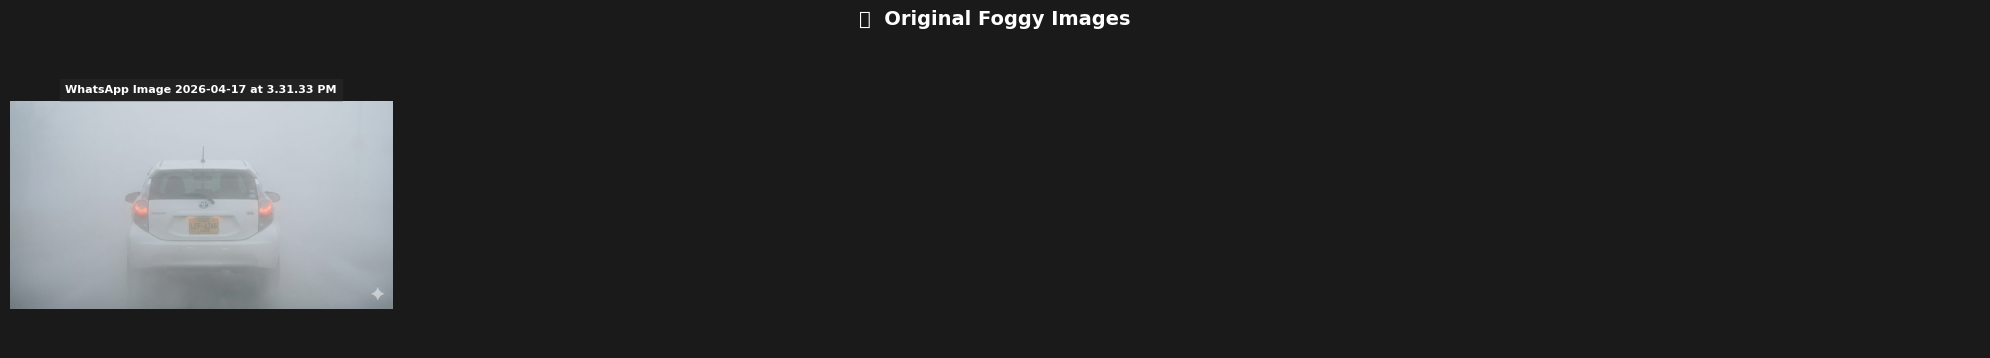

📊 Foggy grid saved  (1 images)


In [ ]:
# ============================================================
# Grid 1: Show original foggy images
# ============================================================
n    = len(image_paths)
cols = 5
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(cols * 4, rows * 3.5))
axes = np.array(axes).flatten()

for i, p in enumerate(image_paths):
    img = Image.open(p).convert('RGB')
    axes[i].imshow(img)
    axes[i].set_title(Path(p).stem, fontsize=8, color='white',
                      fontweight='bold', backgroundcolor='#222')
    axes[i].axis('off')

for j in range(n, len(axes)):
    axes[j].axis('off')

fig.patch.set_facecolor('#1a1a1a')
plt.suptitle('📷  Original Foggy Images', fontsize=14,
             color='white', fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('/content/grid_foggy.png', dpi=150,
            bbox_inches='tight', facecolor='#1a1a1a')
plt.show()
print(f"📊 Foggy grid saved  ({n} images)")

🔄 Removing fog from images...

  ✅ WhatsApp Image 2026-04-17 at 3.31.33 PM.jpeg

✅ 1 images defogged.



/tmp/ipykernel_4667/631919750.py:43: UserWarning: Glyph 10024 (\N{SPARKLES}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4667/631919750.py:44: UserWarning: Glyph 10024 (\N{SPARKLES}) missing from font(s) DejaVu Sans.
  plt.savefig('/content/grid_preprocessed.png', dpi=150,
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 10024 (\N{SPARKLES}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


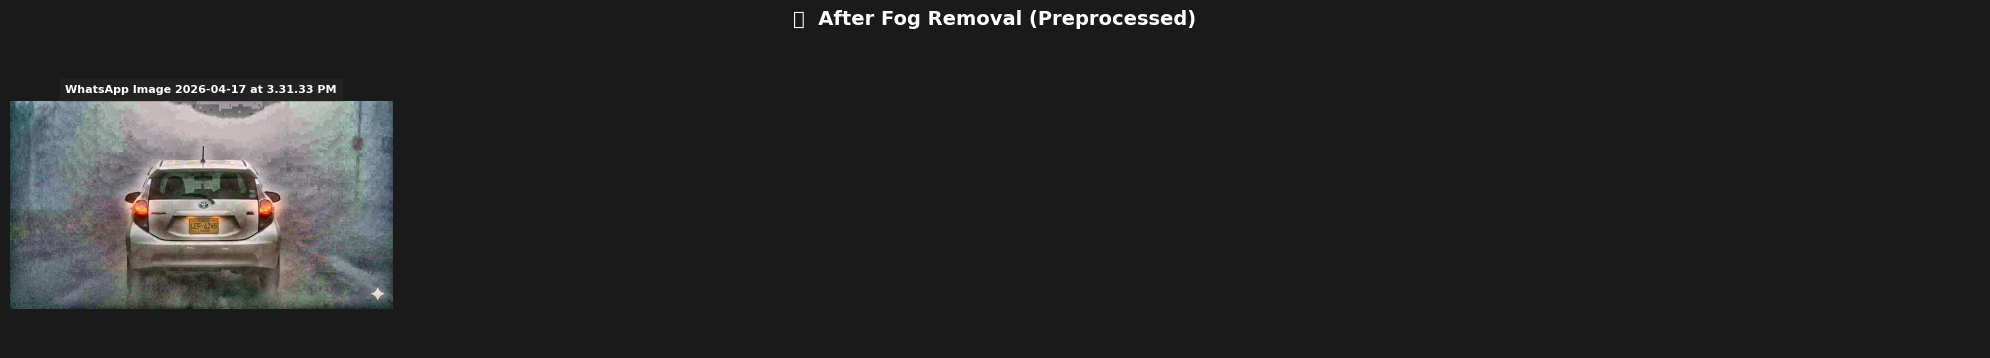

📊 Preprocessed grid saved  (1 images)


In [ ]:
# ============================================================
# Apply fog removal and save preprocessed images
# ============================================================
PREPROCESSED_DIR = Path('/content/preprocessed_images')
PREPROCESSED_DIR.mkdir(exist_ok=True)

preprocessed_paths = []
print("🔄 Removing fog from images...\n")

for p in image_paths:
    foggy = Image.open(p).convert('RGB')
    clear = defog_image(foggy)
    out_path = PREPROCESSED_DIR / p.name
    clear.save(str(out_path))
    preprocessed_paths.append(out_path)
    print(f"  ✅ {p.name}")

print(f"\n✅ {len(preprocessed_paths)} images defogged.\n")

# ============================================================
# Grid 2: Show preprocessed (clear) images
# ============================================================
n    = len(preprocessed_paths)
cols = 5
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(cols * 4, rows * 3.5))
axes = np.array(axes).flatten()

for i, p in enumerate(preprocessed_paths):
    img = Image.open(p).convert('RGB')
    axes[i].imshow(img)
    axes[i].set_title(Path(p).stem, fontsize=8, color='white',
                      fontweight='bold', backgroundcolor='#222')
    axes[i].axis('off')

for j in range(n, len(axes)):
    axes[j].axis('off')

fig.patch.set_facecolor('#1a1a1a')
plt.suptitle('✨  After Fog Removal (Preprocessed)', fontsize=14,
             color='white', fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('/content/grid_preprocessed.png', dpi=150,
            bbox_inches='tight', facecolor='#1a1a1a')
plt.show()
print(f"📊 Preprocessed grid saved  ({n} images)")

In [ ]:
# ============================================================
# Run plate detection + OCR + vehicle classification on PREPROCESSED images
# ============================================================
PLATE_CONF = 0.25
CHAR_CONF  = 0.25

results_summary = []

print("🔄 Detecting plates & classifying vehicles on preprocessed images...\n")
for img_path in preprocessed_paths:
    annotated_img, plates, vehicle = process_single_image(
        img_path, plate_model, char_model,
        plate_conf=PLATE_CONF,
        char_conf=CHAR_CONF
    )
    results_summary.append((img_path.name, annotated_img, plates, vehicle))
    print(f"  ✅  {img_path.name:<30}  →  Plate: {', '.join(plates):<20}  Vehicle: {vehicle}")

print(f"\n🏁 Done. Processed {len(results_summary)} preprocessed image(s).")

🔄 Detecting plates & classifying vehicles on preprocessed images...

  ✅  WhatsApp Image 2026-04-17 at 3.31.33 PM.jpeg  →  Plate: LEF-6245              Vehicle: Toyota_Aqua 1st Generation

🏁 Done. Processed 1 preprocessed image(s).


/tmp/ipykernel_4667/3254489802.py:39: UserWarning: Glyph 128663 (\N{AUTOMOBILE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4667/3254489802.py:40: UserWarning: Glyph 128663 (\N{AUTOMOBILE}) missing from font(s) DejaVu Sans.
  plt.savefig('/content/batch_results.png', dpi=180,
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128663 (\N{AUTOMOBILE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


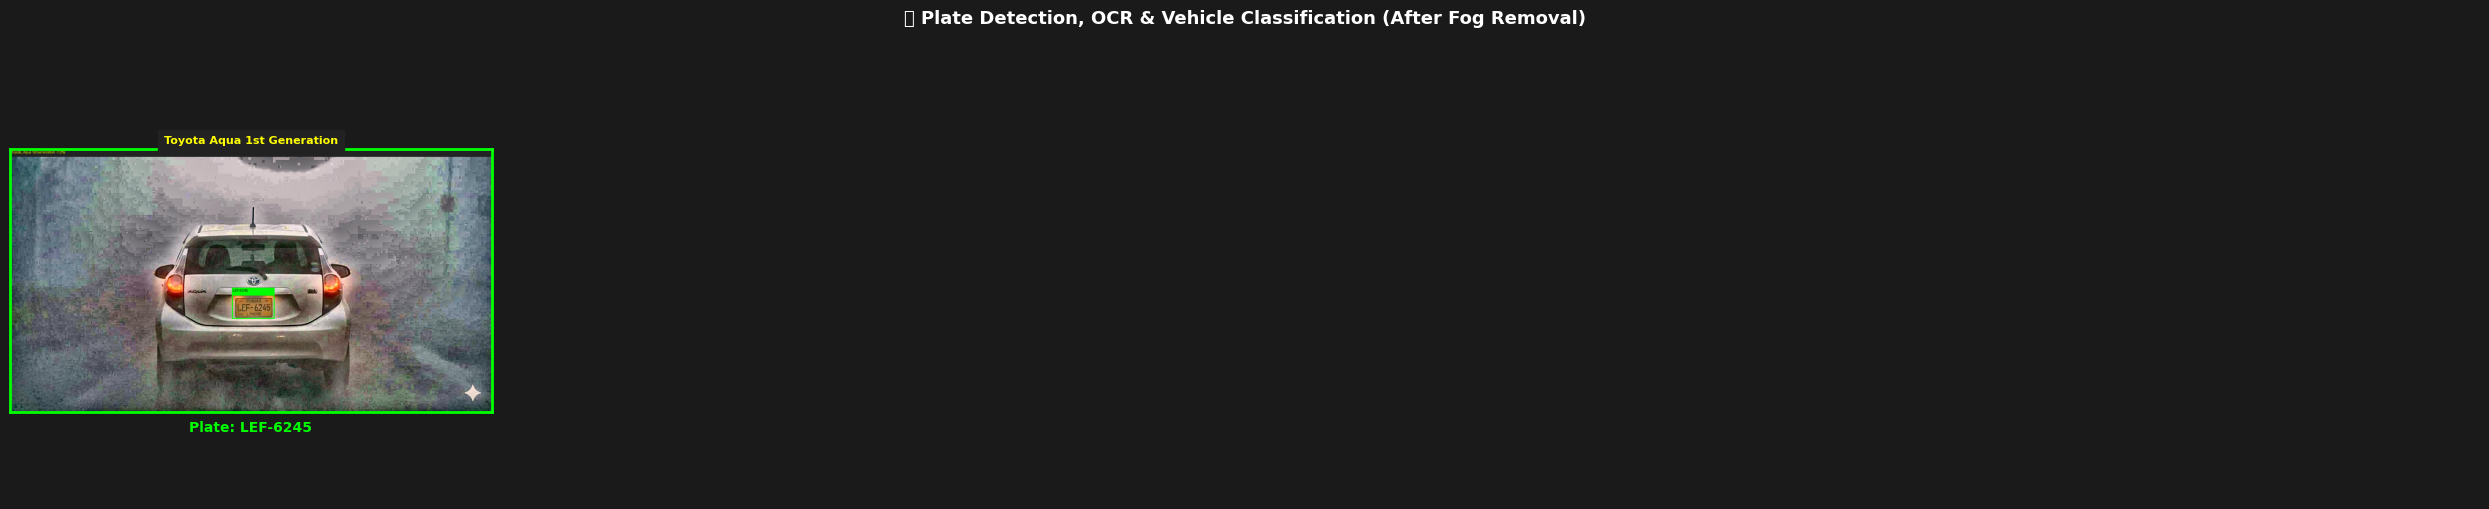

📊 Detection results grid saved to /content/batch_results.png


In [ ]:
# ============================================================
# Grid 3: Plate detection + OCR + Vehicle Make/Model results
# ============================================================
n    = len(results_summary)
cols = 5
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(cols * 5, rows * 5))
axes = np.array(axes).flatten()

for i, (fname, ann_img, plates, vehicle) in enumerate(results_summary):
    axes[i].imshow(ann_img)
    short_name = Path(fname).stem

    axes[i].set_title(
        vehicle.replace('_', ' '), fontsize=8, color='yellow',
        fontweight='bold', pad=4
    )
    axes[i].set_xlabel(
        f"Plate: {', '.join(plates)}", fontsize=10, color='lime',
        fontweight='bold', labelpad=6
    )
    axes[i].tick_params(left=False, bottom=False,
                        labelleft=False, labelbottom=False)
    axes[i].title.set_backgroundcolor('#222222')

    for spine in axes[i].spines.values():
        spine.set_edgecolor('lime')
        spine.set_linewidth(2)

for j in range(n, len(axes)):
    axes[j].axis('off')

fig.patch.set_facecolor('#1a1a1a')
plt.suptitle('🚗 Plate Detection, OCR & Vehicle Classification (After Fog Removal)',
             fontsize=13, color='white', fontweight='bold',
             y=1.01, backgroundcolor='#1a1a1a')

plt.tight_layout()
plt.savefig('/content/batch_results.png', dpi=180,
            bbox_inches='tight', facecolor='#1a1a1a')
plt.show()
print("📊 Detection results grid saved to /content/batch_results.png")

In [ ]:
# ============================================================
# Upload Night / Low-Light Images
# ============================================================
from google.colab import files

MAX_NIGHT_IMAGES = 10
print(f"📂 Upload up to {MAX_NIGHT_IMAGES} night / low-light images (JPG / PNG / BMP / WEBP)...")
uploaded_night = files.upload()

NIGHT_UPLOAD_DIR = Path('/content/uploaded_night_images')
NIGHT_UPLOAD_DIR.mkdir(exist_ok=True)
night_image_paths = []

if not uploaded_night:
    print("❌ No files uploaded.")
else:
    supported = {'jpg', 'jpeg', 'png', 'bmp', 'webp', 'tif', 'tiff'}
    for fname, data in list(uploaded_night.items())[:MAX_NIGHT_IMAGES]:
        dest = NIGHT_UPLOAD_DIR / fname
        dest.write_bytes(data)
        if dest.suffix.lower().lstrip('.') not in supported:
            new_dest = dest.with_suffix('.jpg')
            Image.open(dest).convert('RGB').save(new_dest, 'JPEG')
            dest = new_dest
        night_image_paths.append(dest)

    if len(uploaded_night) > MAX_NIGHT_IMAGES:
        print(f"⚠️  Only first {MAX_NIGHT_IMAGES} of {len(uploaded_night)} uploads accepted.")
    print(f"\n✅ {len(night_image_paths)} night image(s) ready for processing.")

📂 Upload up to 10 night / low-light images (JPG / PNG / BMP / WEBP)...


Saving WhatsApp Image 2026-04-17 at 6.01.02 PM.jpeg to WhatsApp Image 2026-04-17 at 6.01.02 PM.jpeg
Saving WhatsApp Image 2026-04-17 at 5.38.48 PM.jpeg to WhatsApp Image 2026-04-17 at 5.38.48 PM.jpeg
Saving WhatsApp Image 2026-04-17 at 5.15.47 PM.jpeg to WhatsApp Image 2026-04-17 at 5.15.47 PM.jpeg
Saving WhatsApp Image 2026-04-17 at 4.33.20 PM.jpeg to WhatsApp Image 2026-04-17 at 4.33.20 PM.jpeg

✅ 4 night image(s) ready for processing.


/tmp/ipykernel_4667/3481637182.py:24: UserWarning: Glyph 127769 (\N{CRESCENT MOON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4667/3481637182.py:25: UserWarning: Glyph 127769 (\N{CRESCENT MOON}) missing from font(s) DejaVu Sans.
  plt.savefig('/content/grid_night.png', dpi=150,
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127769 (\N{CRESCENT MOON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


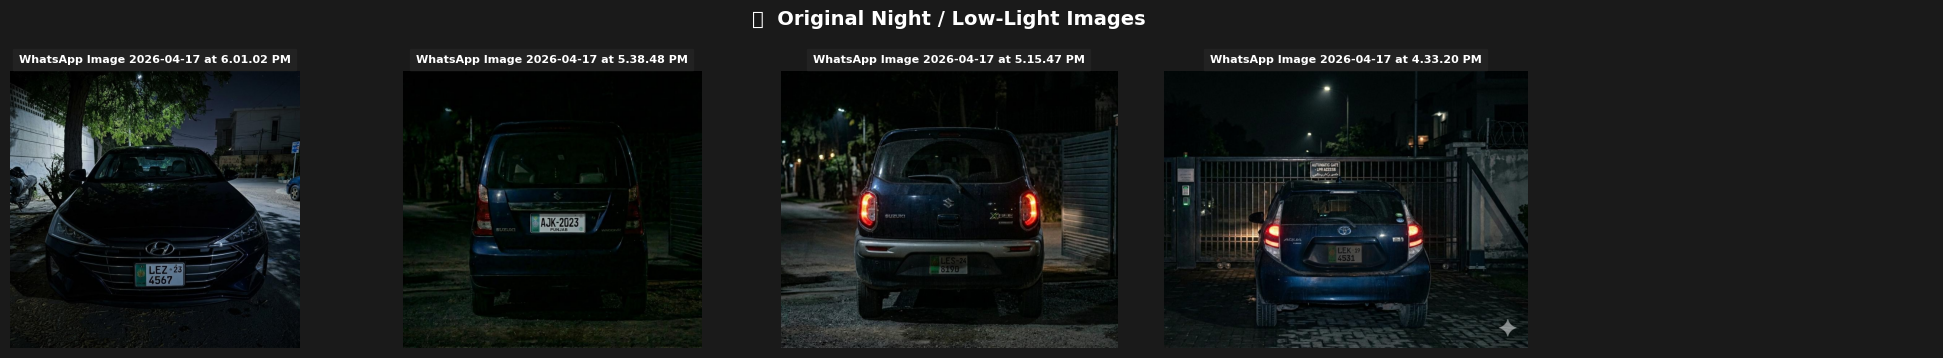

📊 Night grid saved  (4 images)


In [ ]:
# ============================================================
# Grid 7: Original night / low-light images
# ============================================================
n    = len(night_image_paths)
cols = 5
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(cols * 4, rows * 3.5))
axes = np.array(axes).flatten()

for i, p in enumerate(night_image_paths):
    img = Image.open(p).convert('RGB')
    axes[i].imshow(img)
    axes[i].set_title(Path(p).stem, fontsize=8, color='white',
                      fontweight='bold', backgroundcolor='#222')
    axes[i].axis('off')

for j in range(n, len(axes)):
    axes[j].axis('off')

fig.patch.set_facecolor('#1a1a1a')
plt.suptitle('🌙  Original Night / Low-Light Images', fontsize=14,
             color='white', fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('/content/grid_night.png', dpi=150,
            bbox_inches='tight', facecolor='#1a1a1a')
plt.show()
print(f"📊 Night grid saved  ({n} images)")

OK: preprocess_night, preprocess_image, denight_image, show_preprocess_side_by_side, show_preprocess_pair
🔄 Enhancing night images...

  ✅ WhatsApp Image 2026-04-17 at 6.01.02 PM.jpeg
  ✅ WhatsApp Image 2026-04-17 at 5.38.48 PM.jpeg
  ✅ WhatsApp Image 2026-04-17 at 5.15.47 PM.jpeg
  ✅ WhatsApp Image 2026-04-17 at 4.33.20 PM.jpeg

✅ 4 night image(s) enhanced.



/tmp/ipykernel_4667/1920856482.py:170: UserWarning: Glyph 10024 (\N{SPARKLES}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4667/1920856482.py:171: UserWarning: Glyph 10024 (\N{SPARKLES}) missing from font(s) DejaVu Sans.
  plt.savefig('/content/grid_denighted.png', dpi=150,


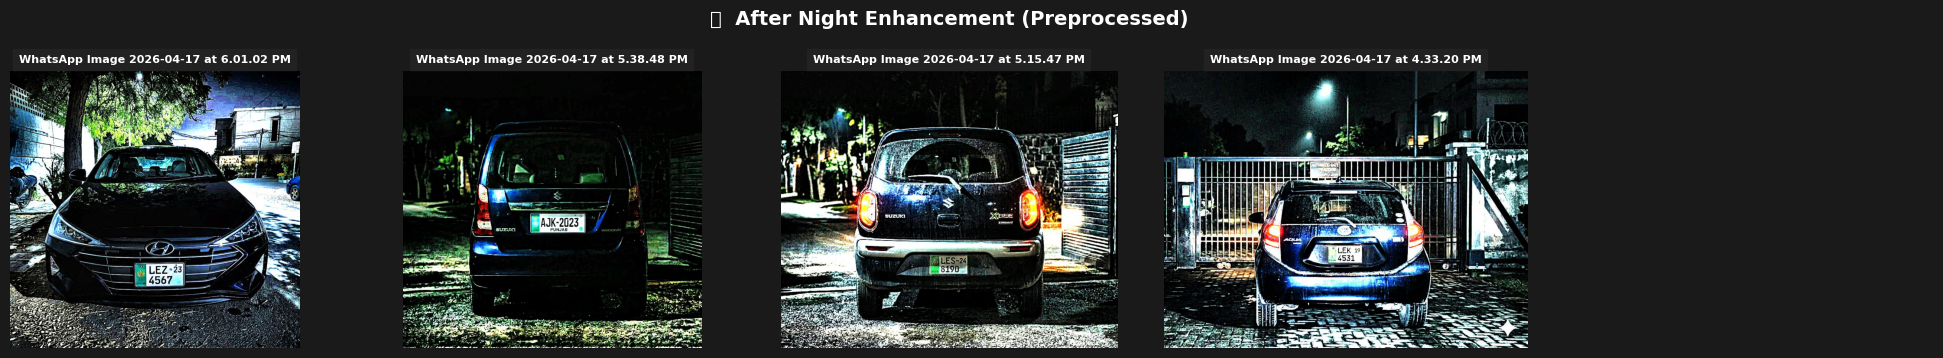

📊 Denighted grid saved  (4 images)


In [ ]:
# ============================================================
# AV Gate — night preprocessing (BGR)
# Night: LAB L-channel CLAHE + gamma + color (no global hist-eq, no grayscale)
# ============================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image


def preprocess_night(img):
    """Day-like night enhancement: lift brightness/color fully like daytime.

    Pipeline (all on LAB/HSV — never grayscale output):
      1) Black-level lift on L  (strong for very dark frames)
      2) CLAHE on L             (high clip limit, fine tiles)
      3) Strong gamma on BGR    (deep shadow lift, fully adaptive)
      4) Global gain if still dark
      5) Saturation boost       (restore washed-out colors)
      6) Unsharp mask           (recover edges)
    """
    if img is None or img.size == 0:
        return img
    bgr = np.clip(img, 0, 255).astype(np.uint8)

    # ── Step 1: measure darkness ────────────────────────────────────────
    lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB)
    l_ch, a_ch, b_ch = cv2.split(lab)
    mean_l = float(l_ch.mean()) / 255.0

    # ── Step 2: black-level lift on L ───────────────────────────────────
    lift = int(np.clip(55.0 * max(0.0, 0.30 - mean_l) / 0.30, 0, 55))
    if lift > 0:
        l_ch = np.clip(l_ch.astype(np.int16) + lift, 0, 255).astype(np.uint8)

    # ── Step 3: CLAHE on L ──────────────────────────────────────────────
    clahe_clip = float(np.clip(5.0 + (0.45 - min(mean_l, 0.45)) * 12.0, 4.5, 8.5))
    clahe = cv2.createCLAHE(clipLimit=clahe_clip, tileGridSize=(6, 6))
    l_ch = clahe.apply(l_ch)
    bgr = cv2.cvtColor(cv2.merge([l_ch, a_ch, b_ch]), cv2.COLOR_LAB2BGR)

    # ── Step 4: strong adaptive gamma ───────────────────────────────────
    # Darker frames → lower gamma → stronger lift (0.28 for pitch black, 0.60 for dusk)
    gamma = float(np.clip(0.28 + mean_l * 1.20, 0.28, 0.62))
    inv_g = 1.0 / gamma
    lut = np.array([min(255, int(pow(i / 255.0, inv_g) * 255)) for i in range(256)],
                   dtype=np.uint8)
    bgr = cv2.LUT(bgr, lut)

    # ── Step 5: global gain if still dim ────────────────────────────────
    mean_after = float(cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY).mean())
    if mean_after < 100:
        gain = np.clip(130.0 / (mean_after + 1e-3), 1.0, 2.5)
        bgr = np.clip(bgr.astype(np.float32) * gain, 0, 255).astype(np.uint8)

    # ── Step 6: saturation boost (colors look faded after lift) ─────────
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV).astype(np.float32)
    hsv[..., 1] = np.clip(hsv[..., 1] * 1.55, 0, 255)
    bgr = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2BGR)

    # ── Step 7: unsharp mask to recover edges ───────────────────────────
    blur = cv2.GaussianBlur(bgr, (0, 0), 2.5)
    bgr = cv2.addWeighted(bgr, 1.5, blur, -0.5, 0)

    return np.clip(bgr, 0, 255).astype(np.uint8)


def preprocess_image(img, condition):
    """Master dispatcher. condition in {'night','normal'}."""
    c = (condition or "normal").strip().lower()
    if c == "night":
        return preprocess_night(img)
    return np.clip(img, 0, 255).astype(np.uint8).copy()


def denight_image(pil_img):
    """PIL in/out wrapper around preprocess_night."""
    bgr = cv2.cvtColor(np.array(pil_img.convert("RGB")), cv2.COLOR_RGB2BGR)
    out = preprocess_night(bgr)
    return Image.fromarray(cv2.cvtColor(out, cv2.COLOR_BGR2RGB))


def show_preprocess_side_by_side(orig_bgr, suptitle="Original vs preprocessed (testing)"):
    """matplotlib: original | night."""
    pairs = [
        ("night", preprocess_night(orig_bgr.copy())),
    ]
    fig, axes = plt.subplots(len(pairs), 2, figsize=(11, 4.2 * len(pairs)))
    if len(pairs) == 1:
        axes = np.array([axes])
    o_rgb = cv2.cvtColor(orig_bgr, cv2.COLOR_BGR2RGB)
    for i, (name, proc) in enumerate(pairs):
        axes[i, 0].imshow(o_rgb)
        axes[i, 0].set_title("original")
        axes[i, 0].axis("off")
        axes[i, 1].imshow(cv2.cvtColor(proc, cv2.COLOR_BGR2RGB))
        axes[i, 1].set_title("after preprocess_%s" % name)
        axes[i, 1].axis("off")
    fig.patch.set_facecolor("#1a1a1a")
    plt.suptitle(suptitle, color="white", fontsize=13)
    plt.tight_layout()
    plt.show()


def show_preprocess_pair(orig_bgr, condition, title=None):
    """Single-condition QA: original | preprocess_image(..., condition)."""
    c = (condition or "normal").strip().lower()
    proc = preprocess_image(orig_bgr.copy(), c)
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].imshow(cv2.cvtColor(orig_bgr, cv2.COLOR_BGR2RGB))
    ax[0].set_title("original")
    ax[0].axis("off")
    ax[1].imshow(cv2.cvtColor(proc, cv2.COLOR_BGR2RGB))
    ax[1].set_title("after preprocess_image(..., %r)" % c)
    ax[1].axis("off")
    fig.patch.set_facecolor("#1a1a1a")
    for a in ax:
        a.title.set_color("white")
    plt.suptitle(title or ("QA: %s" % c), color="white", fontsize=12)
    plt.tight_layout()
    plt.show()


print(
    "OK: preprocess_night, preprocess_image, denight_image, "
    "show_preprocess_side_by_side, show_preprocess_pair"
)

# ============================================================
# Night enhancement + Grid 8: after preprocess_night
# ============================================================
NIGHT_PREPROCESSED_DIR = Path('/content/denighted_images')
NIGHT_PREPROCESSED_DIR.mkdir(exist_ok=True)

denighted_paths = []
print("🔄 Enhancing night images...\n")

for p in night_image_paths:
    pil_in = Image.open(p).convert('RGB')
    clear = denight_image(pil_in)
    out_path = NIGHT_PREPROCESSED_DIR / p.name
    clear.save(str(out_path))
    denighted_paths.append(out_path)
    print(f"  ✅ {p.name}")

print(f"\n✅ {len(denighted_paths)} night image(s) enhanced.\n")

n    = len(denighted_paths)
cols = 5
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(cols * 4, rows * 3.5))
axes = np.array(axes).flatten()

for i, p in enumerate(denighted_paths):
    img = Image.open(p).convert('RGB')
    axes[i].imshow(img)
    axes[i].set_title(Path(p).stem, fontsize=8, color='white',
                      fontweight='bold', backgroundcolor='#222')
    axes[i].axis('off')

for j in range(n, len(axes)):
    axes[j].axis('off')

fig.patch.set_facecolor('#1a1a1a')
plt.suptitle('✨  After Night Enhancement (Preprocessed)', fontsize=14,
             color='white', fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('/content/grid_denighted.png', dpi=150,
            bbox_inches='tight', facecolor='#1a1a1a')
plt.show()
print(f"📊 Denighted grid saved  ({n} images)")

# --- Optional: side-by-side preprocess QA (matplotlib) ---
# After you have a sample BGR image path, uncomment (night paths work once uploads ran):
# bgr = cv2.imread(str(image_paths[0]))   # fog batch
# show_preprocess_side_by_side(bgr)
# bgr = cv2.imread(str(night_image_paths[0]))
# show_preprocess_side_by_side(bgr, suptitle='Night sample')
# show_preprocess_pair(bgr, 'night')   # single condition: original | processed


In [ ]:
# ============================================================
# Plate detection + OCR + vehicle classification (after night enhancement)
# ============================================================
night_results_summary = []

print("🔄 Detecting plates & classifying vehicles on denighted images...\n")
for img_path in denighted_paths:
    annotated_img, plates, vehicle = process_single_image(
        img_path, plate_model, char_model,
        plate_conf=PLATE_CONF,
        char_conf=CHAR_CONF
    )
    night_results_summary.append((img_path.name, annotated_img, plates, vehicle))
    print(f"  ✅  {img_path.name:<30}  →  Plate: {', '.join(plates):<20}  Vehicle: {vehicle}")

print(f"\n🏁 Done. Processed {len(night_results_summary)} denighted image(s).")

🔄 Detecting plates & classifying vehicles on denighted images...

  ✅  WhatsApp Image 2026-04-17 at 6.01.02 PM.jpeg  →  Plate: LEZ-4567              Vehicle: Hyundai_elantra_gen 2019 2020
  ✅  WhatsApp Image 2026-04-17 at 5.38.48 PM.jpeg  →  Plate: AJK-2023              Vehicle: Suzuki_Wagon R 1st Generation
  ✅  WhatsApp Image 2026-04-17 at 5.15.47 PM.jpeg  →  Plate: LES-8190              Vehicle: Suzuki_Xbee
  ✅  WhatsApp Image 2026-04-17 at 4.33.20 PM.jpeg  →  Plate: LEK-4531              Vehicle: Toyota_Aqua 1st Generation

🏁 Done. Processed 4 denighted image(s).


/tmp/ipykernel_4667/3008041866.py:37: UserWarning: Glyph 128663 (\N{AUTOMOBILE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4667/3008041866.py:38: UserWarning: Glyph 128663 (\N{AUTOMOBILE}) missing from font(s) DejaVu Sans.
  plt.savefig('/content/night_batch_results.png', dpi=180,


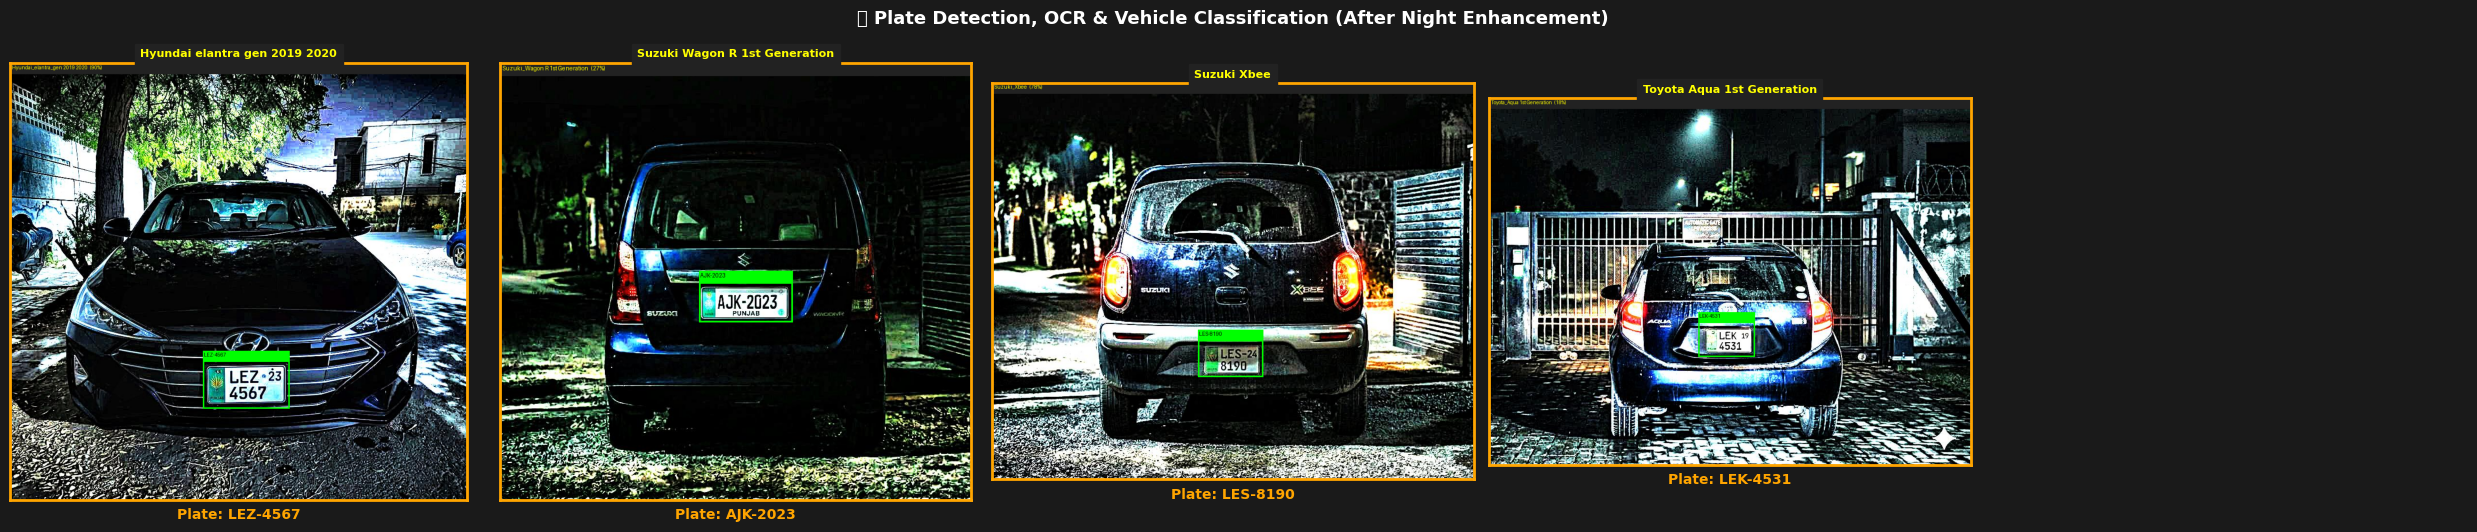

📊 Night batch results saved to /content/night_batch_results.png


In [ ]:
# ============================================================
# Grid 9: Night — plate detection + OCR + vehicle classification
# ============================================================
n    = len(night_results_summary)
cols = 5
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(cols * 5, rows * 5))
axes = np.array(axes).flatten()

for i, (fname, ann_img, plates, vehicle) in enumerate(night_results_summary):
    axes[i].imshow(ann_img)
    axes[i].set_title(
        vehicle.replace('_', ' '), fontsize=8, color='yellow',
        fontweight='bold', pad=4
    )
    axes[i].set_xlabel(
        f"Plate: {', '.join(plates)}", fontsize=10, color='orange',
        fontweight='bold', labelpad=6
    )
    axes[i].tick_params(left=False, bottom=False,
                        labelleft=False, labelbottom=False)
    axes[i].title.set_backgroundcolor('#222222')

    for spine in axes[i].spines.values():
        spine.set_edgecolor('orange')
        spine.set_linewidth(2)

for j in range(n, len(axes)):
    axes[j].axis('off')

fig.patch.set_facecolor('#1a1a1a')
plt.suptitle('🚗 Plate Detection, OCR & Vehicle Classification (After Night Enhancement)',
             fontsize=13, color='white', fontweight='bold',
             y=1.01, backgroundcolor='#1a1a1a')

plt.tight_layout()
plt.savefig('/content/night_batch_results.png', dpi=180,
            bbox_inches='tight', facecolor='#1a1a1a')
plt.show()
print("📊 Night batch results saved to /content/night_batch_results.png")

In [ ]:
# ============================================================
# Upload Rainy Images
# ============================================================
from google.colab import files

MAX_RAIN_IMAGES = 10
print(f"📂 Upload up to {MAX_RAIN_IMAGES} rainy images (JPG / PNG / BMP / WEBP)...")
uploaded_rain = files.upload()

RAIN_UPLOAD_DIR = Path('/content/uploaded_rainy_images')
RAIN_UPLOAD_DIR.mkdir(exist_ok=True)
rain_image_paths = []

if not uploaded_rain:
    print("❌ No files uploaded.")
else:
    supported = {'jpg', 'jpeg', 'png', 'bmp', 'webp', 'tif', 'tiff'}
    for fname, data in list(uploaded_rain.items())[:MAX_RAIN_IMAGES]:
        dest = RAIN_UPLOAD_DIR / fname
        dest.write_bytes(data)
        if dest.suffix.lower().lstrip('.') not in supported:
            new_dest = dest.with_suffix('.jpg')
            Image.open(dest).convert('RGB').save(new_dest, 'JPEG')
            dest = new_dest
        rain_image_paths.append(dest)

    if len(uploaded_rain) > MAX_RAIN_IMAGES:
        print(f"⚠️  Only first {MAX_RAIN_IMAGES} of {len(uploaded_rain)} uploads accepted.")
    print(f"\n✅ {len(rain_image_paths)} rainy image(s) ready for processing.")

📂 Upload up to 10 rainy images (JPG / PNG / BMP / WEBP)...


Saving WhatsApp Image 2026-04-17 at 1.00.01 PM.jpeg to WhatsApp Image 2026-04-17 at 1.00.01 PM.jpeg
Saving WhatsApp Image 2026-04-17 at 1.00.12 PM.jpeg to WhatsApp Image 2026-04-17 at 1.00.12 PM.jpeg
Saving WhatsApp Image 2026-04-17 at 1.00.13 PM.jpeg to WhatsApp Image 2026-04-17 at 1.00.13 PM.jpeg

✅ 3 rainy image(s) ready for processing.


✅ derain_image() — streak-focused rain removal pipeline defined.


/tmp/ipykernel_4667/1906864296.py:262: UserWarning: Glyph 127783 (\N{CLOUD WITH RAIN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4667/1906864296.py:263: UserWarning: Glyph 127783 (\N{CLOUD WITH RAIN}) missing from font(s) DejaVu Sans.
  plt.savefig("/content/grid_rainy.png", dpi=150, bbox_inches="tight", facecolor="#1a1a1a")
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127783 (\N{CLOUD WITH RAIN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


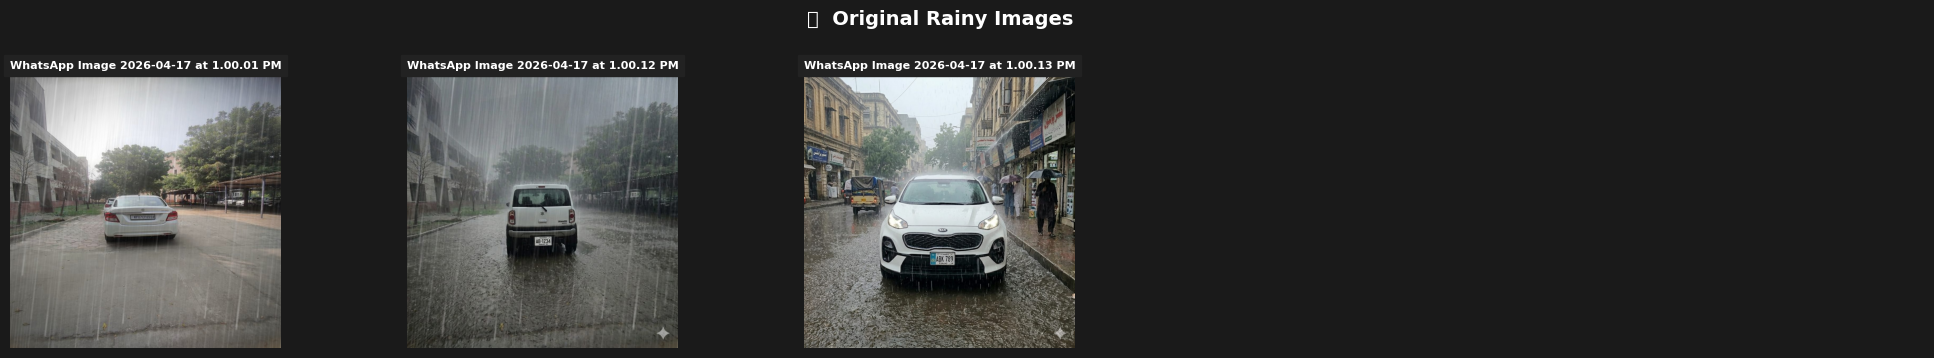

📊 Rainy grid saved  (3 images)


In [ ]:
# ============================================================
# Grid 4: Show original rainy images
# ============================================================
# ============================================================
# Rain Removal Preprocessing — streak-focused pipeline (classic CV)
# Targets long bright rain lines (vertical / slight diagonal) while
# preserving plates, edges, and headlight glow via LAB + soft masks.
# ============================================================

from numpy.lib.stride_tricks import sliding_window_view


def _vertical_median_1d(ch_u8, ksize):
    """True vertical median filter (per-column), ksize odd."""
    ksize = int(ksize) | 1
    if ksize < 3:
        return ch_u8
    pad = ksize // 2
    g = ch_u8.astype(np.float64)
    padded = np.pad(g, ((pad, pad), (0, 0)), mode="reflect")
    win = sliding_window_view(padded, ksize, axis=0)
    return np.median(win, axis=-1).astype(np.uint8)


def _guided_vertical_filter(bgr, ksize):
    """Vertical median filter, each BGR channel."""
    return np.stack(
        [_vertical_median_1d(bgr[:, :, c], ksize) for c in range(3)], axis=-1
    )


def _warp_rotate_gray(gray, angle_deg, border=cv2.BORDER_REFLECT):
    h, w = gray.shape[:2]
    M = cv2.getRotationMatrix2D((w * 0.5, h * 0.5), float(angle_deg), 1.0)
    return cv2.warpAffine(gray, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=border)


def _horizontal_open_residual(gray_u8):
    """Bright thin vertical-ish structures: I - morph_open(I, wide horizontal SE)."""
    acc = np.zeros_like(gray_u8, dtype=np.float32)
    for kw in (17, 25, 35, 47):
        kern = cv2.getStructuringElement(cv2.MORPH_RECT, (kw, 1))
        opened = cv2.morphologyEx(gray_u8, cv2.MORPH_OPEN, kern)
        acc = np.maximum(acc, cv2.subtract(gray_u8, opened).astype(np.float32))
    return acc


def _vertical_tophat_stack(gray_u8):
    acc = np.zeros_like(gray_u8, dtype=np.float32)
    for kh in (13, 21, 31, 41):
        v = cv2.getStructuringElement(cv2.MORPH_RECT, (1, kh))
        acc = np.maximum(acc, cv2.morphologyEx(gray_u8, cv2.MORPH_TOPHAT, v).astype(np.float32))
    return acc


def _base_streak_strength(gray_u8):
    ho = _horizontal_open_residual(gray_u8)
    vt = _vertical_tophat_stack(gray_u8)
    combined = np.maximum(ho, vt * 0.85)
    combined = cv2.GaussianBlur(combined, (3, 3), 0)
    p99 = float(np.percentile(combined, 99.4))
    p99 = max(p99, 8.0)
    return np.clip(combined / p99, 0.0, 1.0).astype(np.float32)


def _streak_strength_multi_angle(gray_u8):
    """Union streak evidence over small rotations so diagonals are caught."""
    h, w = gray_u8.shape[:2]
    acc = _base_streak_strength(gray_u8)
    for ang in (-12, -8, -4, 4, 8, 12):
        rot = _warp_rotate_gray(gray_u8, ang)
        m = _base_streak_strength(rot)
        Minv = cv2.getRotationMatrix2D((w * 0.5, h * 0.5), float(-ang), 1.0)
        back = cv2.warpAffine(m, Minv, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)
        acc = np.maximum(acc, back)
    return acc


def _soft_edge_importance(bgr):
    """0..1 map: strong structure should receive less aggressive rain suppression."""
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
    mag = cv2.magnitude(gx, gy)
    mag = cv2.normalize(mag, None, 0.0, 1.0, cv2.NORM_MINMAX)
    mag = cv2.GaussianBlur(mag, (0, 0), sigmaX=2.0)
    return np.clip(mag * 1.8, 0.0, 1.0)


def _build_protection_mask(bgr):
    """Protect structured regions (plates, edges) from inpainting."""
    smoothed = cv2.bilateralFilter(bgr, 11, 80, 80)
    gray = cv2.cvtColor(smoothed, cv2.COLOR_BGR2GRAY)
    edges = cv2.Canny(gray, 40, 120)
    density = cv2.blur(edges.astype(np.float32), (31, 31))
    _, struct_mask = cv2.threshold(density, 10.0, 255, cv2.THRESH_BINARY)
    struct_mask = cv2.dilate(struct_mask.astype(np.uint8), np.ones((15, 15), np.uint8), iterations=2)
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    _, bright_mask = cv2.threshold(hsv[:, :, 2], 220, 255, cv2.THRESH_BINARY)
    bright_mask = cv2.dilate(bright_mask, np.ones((7, 7), np.uint8), iterations=1)
    protect = cv2.bitwise_or(struct_mask, bright_mask)
    return protect


def _frequency_domain_derain(bgr):
    """Attenuate narrow vertical-band energy in FFT (per channel), smooth mask."""
    result = bgr.copy().astype(np.float32)
    rows, cols = bgr.shape[:2]
    crow, ccol = rows // 2, cols // 2
    suppress_w = max(3, cols // 50)
    keep_h = max(8, rows // 18)
    rr = np.arange(rows, dtype=np.float32)[:, None]
    cc = np.arange(cols, dtype=np.float32)[None, :]
    dist_u = np.abs(cc - ccol) / float(suppress_w)
    band = np.clip(1.0 - dist_u, 0.0, 1.0)
    dist_v = np.minimum(np.abs(rr - crow), rows - np.abs(rr - crow))
    side = (dist_v > float(keep_h)).astype(np.float32)
    mask = 1.0 - 0.78 * band * side
    mask[crow - 2 : crow + 3, ccol - 2 : ccol + 3] = 1.0
    for c in range(3):
        ch = bgr[:, :, c].astype(np.float32)
        dft = np.fft.fftshift(np.fft.fft2(ch))
        ch_back = np.real(np.fft.ifft2(np.fft.ifftshift(dft * mask)))
        result[:, :, c] = np.clip(ch_back, 0, 255)
    return result.astype(np.uint8)


def _selective_blend(original, filtered_spatial, filtered_freq, protect_mask, streak_f):
    protect_f = cv2.GaussianBlur(protect_mask.astype(np.float32), (15, 15), 4.0) / 255.0
    streak_f = np.clip(streak_f, 0.0, 1.0)
    streak_f = cv2.GaussianBlur(streak_f.astype(np.float32), (7, 9), 0)

    orig_f = original.astype(np.float64)
    spat_f = filtered_spatial.astype(np.float64)
    freq_f = filtered_freq.astype(np.float64)

    in_streak = spat_f * 0.55 + freq_f * 0.45
    no_streak = orig_f * 0.35 + freq_f * 0.65

    combined = in_streak * streak_f[:, :, None] + no_streak * (1.0 - streak_f[:, :, None])
    result = combined * (1.0 - protect_f[:, :, None]) + orig_f * protect_f[:, :, None]

    diff = result - orig_f
    result = np.where(diff > 6.0, orig_f + 6.0, result)
    return np.clip(result, 0, 255).astype(np.uint8)


def _inpaint_residual_streaks(bgr, protect_mask):
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY).astype(np.float32)
    local_mean = cv2.blur(gray, (1, 27))
    diff = gray - local_mean
    _, spots = cv2.threshold(np.clip(diff, 0, 255).astype(np.uint8), 8, 255, cv2.THRESH_BINARY)

    tiny_kern = cv2.getStructuringElement(cv2.MORPH_RECT, (1, 11))
    mx = np.max(bgr, axis=2).astype(np.uint8)
    tophat = cv2.morphologyEx(mx, cv2.MORPH_TOPHAT, tiny_kern)
    _, dot_mask = cv2.threshold(tophat, 12, 255, cv2.THRESH_BINARY)

    inpaint_mask = cv2.bitwise_or(spots, dot_mask)
    contours, _ = cv2.findContours(inpaint_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    final_mask = np.zeros_like(inpaint_mask)
    for cnt in contours:
        area = cv2.contourArea(cnt)
        if area < 2:
            continue
        x, y, w, h = cv2.boundingRect(cnt)
        aspect = h / max(w, 1)
        if area < 450 or aspect > 1.25:
            cv2.drawContours(final_mask, [cnt], -1, 255, -1)

    final_mask[protect_mask > 0] = 0
    final_mask = cv2.dilate(final_mask, np.ones((3, 3), np.uint8), iterations=1)

    if np.any(final_mask > 0):
        bgr = cv2.inpaint(bgr, final_mask, inpaintRadius=3, flags=cv2.INPAINT_TELEA)
    return bgr


def derain_image(pil_img):
    """
    Remove rain streaks (heavy vertical / diagonal lines) toward a clean night-rain look:
      1) Multi-angle streak strength on luminance
      2) LAB L-channel: subtract localized bright spikes (horizontal morph opening)
      3) Guided vertical median on BGR where streaks are strong
      4) Mild FFT band attenuation + edge-aware blend + inpaint + light bilateral
    """
    bgr = cv2.cvtColor(np.array(pil_img), cv2.COLOR_RGB2BGR)
    original_bgr = bgr.copy()

    gray_u8 = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    streak_raw = _streak_strength_multi_angle(gray_u8)
    edge_keep = _soft_edge_importance(bgr)
    streak_weight = streak_raw * (1.0 - 0.65 * edge_keep)
    streak_weight = cv2.GaussianBlur(streak_weight, (5, 11), 0)
    streak_weight = np.clip(streak_weight * 1.15, 0.0, 1.0)

    protect_mask = _build_protection_mask(bgr)

    # --- LAB: kill thin bright lines mostly in L ---
    lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB)
    L, A, Bc = cv2.split(lab)
    Lf = L.astype(np.float32)
    kern_h = cv2.getStructuringElement(cv2.MORPH_RECT, (43, 1))
    L_open = cv2.morphologyEx(L, cv2.MORPH_OPEN, kern_h).astype(np.float32)
    spike_L = np.clip(Lf - L_open, 0.0, None)
    L2 = np.clip(Lf - 0.92 * streak_weight * spike_L, 0, 255).astype(np.uint8)
    lab2 = cv2.merge((L2, A, Bc))
    bgr = cv2.cvtColor(lab2, cv2.COLOR_LAB2BGR)

    # --- Vertical median where streaks remain ---
    wm = np.clip((streak_weight - 0.12) / 0.55, 0.0, 1.0).astype(np.float32)
    wm = cv2.GaussianBlur(wm, (5, 5), 0)
    vmed = _guided_vertical_filter(bgr, ksize=5)
    bgr_spatial = (bgr.astype(np.float32) * (1.0 - wm[:, :, None]) + vmed.astype(np.float32) * wm[:, :, None]).astype(np.uint8)

    for kextra in (7,):
        vmed2 = _guided_vertical_filter(bgr_spatial, ksize=kextra)
        wm2 = np.clip((streak_weight - 0.35) / 0.5, 0.0, 1.0).astype(np.float32)
        wm2 = cv2.GaussianBlur(wm2, (5, 5), 0)
        bgr_spatial = (
            bgr_spatial.astype(np.float32) * (1.0 - wm2[:, :, None])
            + vmed2.astype(np.float32) * wm2[:, :, None]
        ).astype(np.uint8)

    bgr_freq = _frequency_domain_derain(bgr_spatial)
    bgr = _selective_blend(original_bgr, bgr_spatial, bgr_freq, protect_mask, streak_weight)
    bgr = _inpaint_residual_streaks(bgr, protect_mask)

    bgr_smooth = cv2.bilateralFilter(bgr, 5, 28, 28)
    protect_soft = cv2.GaussianBlur(protect_mask.astype(np.float32), (21, 21), 5.0) / 255.0
    bgr = (
        bgr_smooth.astype(np.float32) * (1.0 - protect_soft[:, :, None])
        + bgr.astype(np.float32) * protect_soft[:, :, None]
    ).astype(np.uint8)

    # Mild local contrast recovery (rain + bilateral flatten texture slightly)
    blur = cv2.GaussianBlur(bgr, (0, 0), 1.2)
    bgr = np.clip(bgr.astype(np.float32) * 1.08 - blur.astype(np.float32) * 0.08, 0, 255).astype(np.uint8)

    return Image.fromarray(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))


print("✅ derain_image() — streak-focused rain removal pipeline defined.")
n = len(rain_image_paths)
cols = 5
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(cols * 4, rows * 3.5))
axes = np.array(axes).flatten()

for i, p in enumerate(rain_image_paths):
    img = Image.open(p).convert("RGB")
    axes[i].imshow(img)
    axes[i].set_title(Path(p).stem, fontsize=8, color="white", fontweight="bold", backgroundcolor="#222")
    axes[i].axis("off")

for j in range(n, len(axes)):
    axes[j].axis("off")

fig.patch.set_facecolor("#1a1a1a")
plt.suptitle("🌧️  Original Rainy Images", fontsize=14, color="white", fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("/content/grid_rainy.png", dpi=150, bbox_inches="tight", facecolor="#1a1a1a")
plt.show()
print(f"📊 Rainy grid saved  ({n} images)")


🔄 Removing rain from images...

  ✅ WhatsApp Image 2026-04-17 at 1.00.01 PM.jpeg
  ✅ WhatsApp Image 2026-04-17 at 1.00.12 PM.jpeg
  ✅ WhatsApp Image 2026-04-17 at 1.00.13 PM.jpeg

✅ 3 images derained.



/tmp/ipykernel_4667/380673791.py:43: UserWarning: Glyph 10024 (\N{SPARKLES}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4667/380673791.py:44: UserWarning: Glyph 10024 (\N{SPARKLES}) missing from font(s) DejaVu Sans.
  plt.savefig('/content/grid_derained.png', dpi=150,


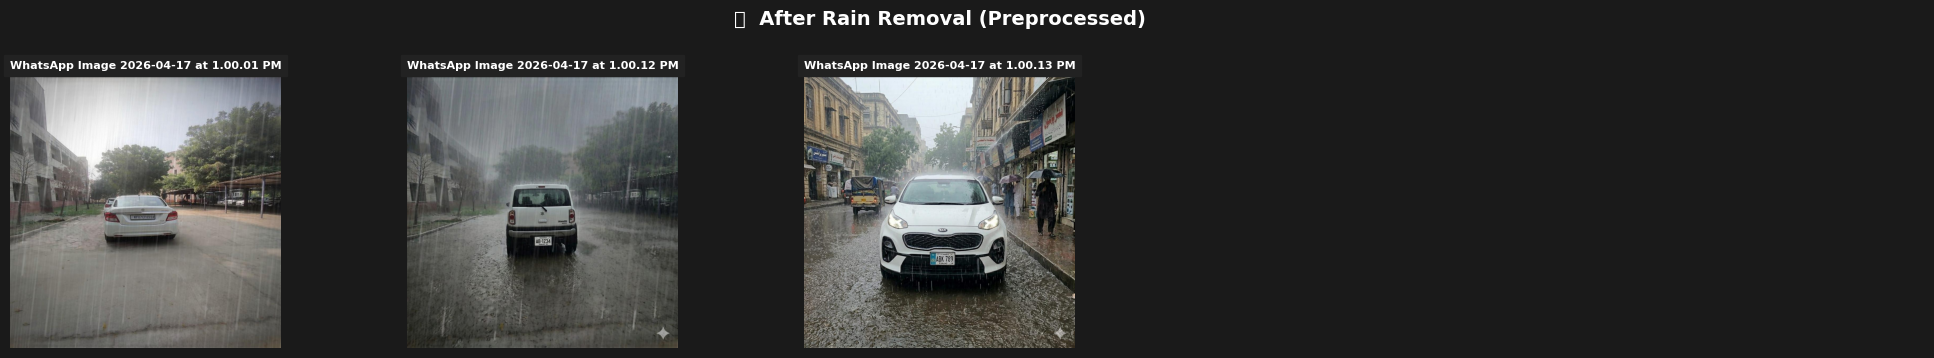

📊 Derained grid saved  (3 images)


In [ ]:
# ============================================================
# Apply rain removal and save preprocessed images
# ============================================================
RAIN_PREPROCESSED_DIR = Path('/content/derained_images')
RAIN_PREPROCESSED_DIR.mkdir(exist_ok=True)

derained_paths = []
print("🔄 Removing rain from images...\n")

for p in rain_image_paths:
    rainy = Image.open(p).convert('RGB')
    clear = derain_image(rainy)
    out_path = RAIN_PREPROCESSED_DIR / p.name
    clear.save(str(out_path))
    derained_paths.append(out_path)
    print(f"  ✅ {p.name}")

print(f"\n✅ {len(derained_paths)} images derained.\n")

# ============================================================
# Grid 5: Show derained (clear) images
# ============================================================
n    = len(derained_paths)
cols = 5
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(cols * 4, rows * 3.5))
axes = np.array(axes).flatten()

for i, p in enumerate(derained_paths):
    img = Image.open(p).convert('RGB')
    axes[i].imshow(img)
    axes[i].set_title(Path(p).stem, fontsize=8, color='white',
                      fontweight='bold', backgroundcolor='#222')
    axes[i].axis('off')

for j in range(n, len(axes)):
    axes[j].axis('off')

fig.patch.set_facecolor('#1a1a1a')
plt.suptitle('✨  After Rain Removal (Preprocessed)', fontsize=14,
             color='white', fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('/content/grid_derained.png', dpi=150,
            bbox_inches='tight', facecolor='#1a1a1a')
plt.show()
print(f"📊 Derained grid saved  ({n} images)")

In [ ]:
# ============================================================
# Run plate detection + OCR + vehicle classification on DERAINED images
# ============================================================
rain_results_summary = []

print("🔄 Detecting plates & classifying vehicles on derained images...\n")
for img_path in derained_paths:
    annotated_img, plates, vehicle = process_single_image(
        img_path, plate_model, char_model,
        plate_conf=PLATE_CONF,
        char_conf=CHAR_CONF
    )
    rain_results_summary.append((img_path.name, annotated_img, plates, vehicle))
    print(f"  ✅  {img_path.name:<30}  →  Plate: {', '.join(plates):<20}  Vehicle: {vehicle}")

print(f"\n🏁 Done. Processed {len(rain_results_summary)} derained image(s).")

In [ ]:
# ============================================================
# Grid 6: Rain — Plate detection + OCR + Vehicle Classification results
# ============================================================
n    = len(rain_results_summary)
cols = 5
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(cols * 5, rows * 5))
axes = np.array(axes).flatten()

for i, (fname, ann_img, plates, vehicle) in enumerate(rain_results_summary):
    axes[i].imshow(ann_img)
    short_name = Path(fname).stem

    axes[i].set_title(
        vehicle.replace('_', ' '), fontsize=8, color='yellow',
        fontweight='bold', pad=4
    )
    axes[i].set_xlabel(
        f"Plate: {', '.join(plates)}", fontsize=10, color='cyan',
        fontweight='bold', labelpad=6
    )
    axes[i].tick_params(left=False, bottom=False,
                        labelleft=False, labelbottom=False)
    axes[i].title.set_backgroundcolor('#222222')

    for spine in axes[i].spines.values():
        spine.set_edgecolor('cyan')
        spine.set_linewidth(2)

for j in range(n, len(axes)):
    axes[j].axis('off')

fig.patch.set_facecolor('#1a1a1a')
plt.suptitle('🚗 Plate Detection, OCR & Vehicle Classification (After Rain Removal)',
             fontsize=13, color='white', fontweight='bold',
             y=1.01, backgroundcolor='#1a1a1a')

plt.tight_layout()
plt.savefig('/content/rain_batch_results.png', dpi=180,
            bbox_inches='tight', facecolor='#1a1a1a')
plt.show()
print("📊 Rain detection results grid saved to /content/rain_batch_results.png")